# 5 — Visualización orientada a preguntas

Un gráfico no es el objetivo: es evidencia para responder una pregunta. En cada ejercicio primero escribí qué querés averiguar, luego construí la agregación y finalmente redactá una conclusión de dos o tres oraciones.

Este notebook se ejecuta manualmente **después** de que el Job termina correctamente; no forma parte del pipeline.

In [0]:
dbutils.widgets.text("student_id", "alumno01", "01 - Identificador")
dbutils.widgets.dropdown("scale", "small", ["test", "small", "demo"], "02 - Escala")

In [0]:
%run ../common/config

In [0]:
from pyspark.sql import functions as F
import matplotlib
import matplotlib.artist
import sys
setattr(matplotlib, 'artist', sys.modules['matplotlib.artist'])
import matplotlib.pyplot as plt

catalog = spark.sql("SELECT current_catalog()").first()[0]
config = CourseConfig(catalog, dbutils.widgets.get("student_id"), dbutils.widgets.get("scale"))
daily = qualified_table(config, "gold_daily_sales")
risk = qualified_table(config, "gold_customer_risk")
batch = qualified_table(config, "gold_batch_summary")
for table in [daily, risk, batch]:
    assert spark.catalog.tableExists(table), f"Falta {table}. Ejecutá primero el Job completo."

## Ejemplo resuelto

**Pregunta:** ¿Qué categoría concentra el mayor monto vendido?

La agregación se hace con Spark. Sólo el resultado pequeño se convierte a Pandas para dibujarlo. Un gráfico de barras ordenado permite comparar categorías; un gráfico de torta haría más difícil comparar valores cercanos.

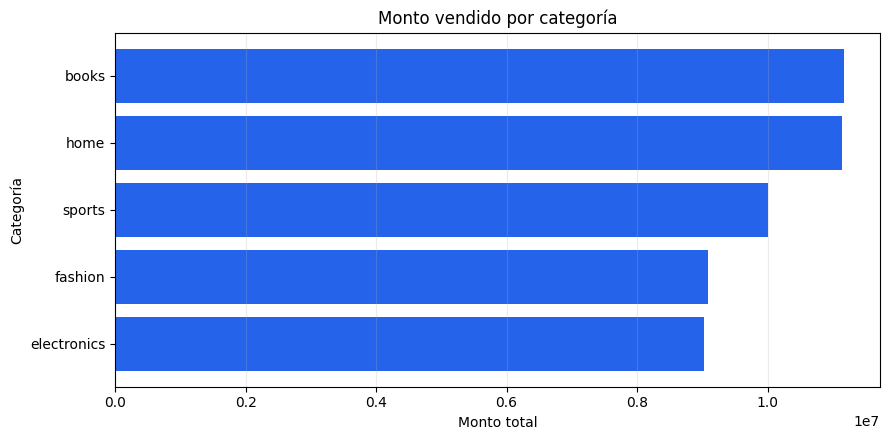

Respuesta: books es la categoría con mayor monto vendido (11,165,281.86).


In [0]:
import matplotlib
import sys
for _sub in ['artist', 'backends', 'colors', 'figure', 'axes', 'lines', 'patches', 'text', 'ticker', 'cm', 'font_manager', 'transforms', 'path', 'markers', 'spines', 'legend', 'axis', 'scale', 'tight_layout', 'gridspec', 'units', 'dates', 'table', 'collections', 'contour', 'image', 'patheffects', 'rcsetup']:
    try:
        __import__(f'matplotlib.{_sub}')
        setattr(matplotlib, _sub, sys.modules[f'matplotlib.{_sub}'])
    except (ImportError, KeyError):
        pass

category_sales = (spark.table(daily)
    .groupBy("category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy(F.desc("total_amount")))

plot_data = category_sales.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["category"], plot_data["total_amount"], color="#2563eb")
ax.set_title("Monto vendido por categoría")
ax.set_xlabel("Monto total")
ax.set_ylabel("Categoría")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = category_sales.first()
print(f"Respuesta: {leader.category} es la categoría con mayor monto vendido ({leader.total_amount:,.2f}).")

## Consigna 1 — Evolución temporal

**Pregunta:** ¿Qué día tuvo el mayor monto vendido y ese día también fue el de mayor cantidad de transacciones?

Construí una visualización temporal que permita comparar ambas métricas sin ocultar sus unidades. Explicá si los dos máximos coinciden y qué implica que coincidan —o no— sobre el ticket promedio. Fuente sugerida: `gold_daily_sales`.

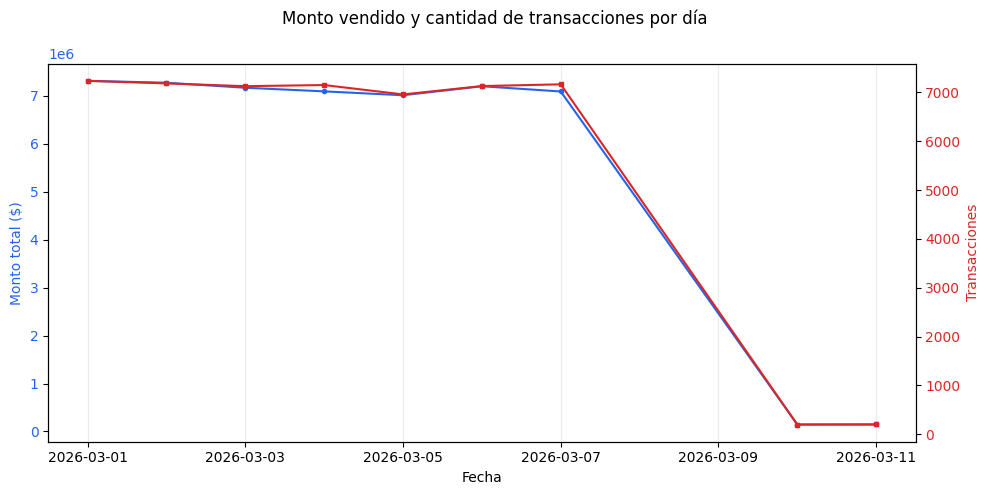

Respuesta: El día con mayor monto es 2026-03-01 ($7,310,840.77). El día con más transacciones es 2026-03-01 (7,236). Coinciden: el ticket promedio es estable entre días.


In [0]:
# Tu solución. Agregá por sale_date antes de convertir el resultado a Pandas.
# Incluí título, ejes, unidades y una respuesta escrita.

import matplotlib
import sys
for _sub in ['artist', 'backends', 'colors', 'figure', 'axes', 'lines', 'patches', 'text', 'ticker', 'cm', 'font_manager', 'transforms', 'path', 'markers', 'spines', 'legend', 'axis', 'scale', 'tight_layout', 'gridspec', 'units', 'dates', 'table', 'collections', 'contour', 'image', 'patheffects', 'rcsetup']:
    try:
        __import__(f'matplotlib.{_sub}')
        setattr(matplotlib, _sub, sys.modules[f'matplotlib.{_sub}'])
    except (ImportError, KeyError):
        pass
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

diario = spark.sql(f"""
SELECT sale_date,
       SUM(total_amount) AS monto_total,
       SUM(transaction_count) AS transacciones
FROM {daily}
GROUP BY sale_date
ORDER BY sale_date
""")

plot_data = diario.toPandas().sort_values("sale_date")

fig, ax1 = plt.subplots(figsize=(10, 5))
color1 = "#2563eb"
ax1.set_xlabel("Fecha")
ax1.set_ylabel("Monto total ($)", color=color1)
ax1.plot(plot_data["sale_date"], plot_data["monto_total"], color=color1, marker="o", markersize=3)
ax1.tick_params(axis="y", labelcolor=color1)
ax1.grid(axis="x", alpha=0.25)

ax2 = ax1.twinx()
color2 = "#dc2626"
ax2.set_ylabel("Transacciones", color=color2)
ax2.plot(plot_data["sale_date"], plot_data["transacciones"], color=color2, marker="s", markersize=3)
ax2.tick_params(axis="y", labelcolor=color2)

fig.suptitle("Monto vendido y cantidad de transacciones por día")
fig.tight_layout()
plt.show()

top_monto = diario.orderBy(F.desc("monto_total")).first()
top_tx = diario.orderBy(F.desc("transacciones")).first()
coinciden = top_monto.sale_date == top_tx.sale_date
print(f"Respuesta: El día con mayor monto es {top_monto.sale_date} (${top_monto.monto_total:,.2f}). "
      f"El día con más transacciones es {top_tx.sale_date} ({top_tx.transacciones:,}). "
      f"{'Coinciden' if coinciden else 'No coinciden'}: el ticket promedio {'es estable' if coinciden else 'varía'} entre días.")

El dia que hubieron mayor numero de transacciones y donde tuvo mayor monto el el 01 de Marzo

## Consigna 2 — Canal y fraude

**Pregunta:** ¿Qué canal de pago presenta la mayor tasa de fraude? ¿La conclusión se sostiene al considerar el número de transacciones de cada canal?

Mostrá tasa y volumen de manera legible. No compares sólo cantidades de fraude: calculá el denominador correcto. Fuente sugerida: `gold_daily_sales`.

In [0]:
# Tu solución. Recalculá la tasa global como suma(fraud_transactions) / suma(transaction_count).
# Evitá promediar directamente fraud_rate entre grupos.

from pyspark.sql import functions as F

canal_fraude = spark.sql(f"""
SELECT payment_channel,
       SUM(transaction_count) AS transacciones,
       SUM(fraud_transactions) AS fraudes,
       ROUND(100 * SUM(fraud_transactions) / SUM(transaction_count), 2) AS tasa_fraude_pct,
       ROUND(SUM(total_amount), 2) AS monto_total
FROM {daily}
GROUP BY payment_channel
ORDER BY tasa_fraude_pct DESC
""")

display(canal_fraude)

payment_channel,transacciones,fraudes,tasa_fraude_pct,monto_total
transfer,16723,2327,13.91,16777156.48
wallet,16724,2169,12.97,16763100.83
card,16902,2119,12.54,16890941.02


Lo mas fraudulento es la transferencia

## Consigna 3 — Concentración geográfica y de producto

**Pregunta:** ¿Qué combinación de país y categoría genera el mayor monto? ¿Existe una categoría dominante en todos los países o cambia según el mercado?

Elegí una visualización que permita comparar simultáneamente países y categorías. Justificá brevemente por qué ese tipo de gráfico es adecuado. Fuente sugerida: `gold_daily_sales`.

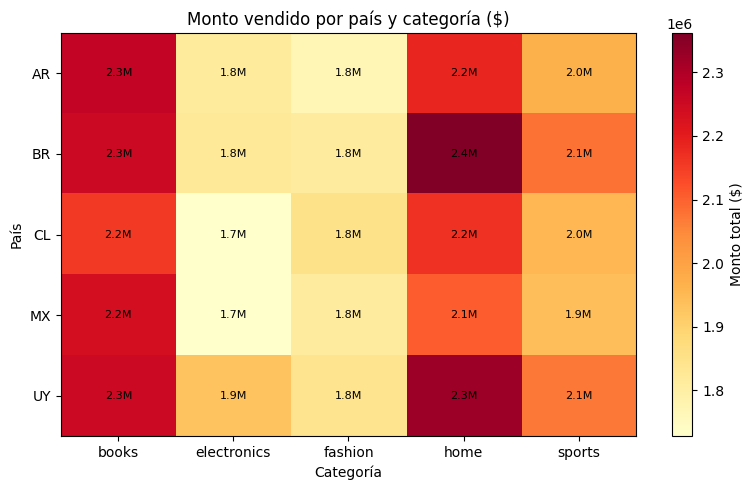

Respuesta: La combinación con mayor monto es BR × home ($2,361,959.97). La categoría #1 varía: BR→home, UY→home, AR→books, MX→books, CL→home.


In [0]:
# Tu solución. Algunas opciones: mapa de calor o barras agrupadas.
# La conclusión debe mencionar tanto el máximo global como las diferencias entre países.

from pyspark.sql import functions as F

import matplotlib
import sys
for _sub in ['artist', 'backends', 'colors', 'figure', 'axes', 'lines', 'patches', 'text', 'ticker', 'cm', 'font_manager', 'transforms', 'path', 'markers', 'spines', 'legend', 'axis', 'scale', 'tight_layout', 'gridspec', 'units', 'dates', 'table', 'collections', 'contour', 'image', 'patheffects', 'rcsetup']:
    try:
        __import__(f'matplotlib.{_sub}')
        setattr(matplotlib, _sub, sys.modules[f'matplotlib.{_sub}'])
    except (ImportError, KeyError):
        pass
import matplotlib.pyplot as plt

pais_categoria = spark.sql(f"""
SELECT country, category,
       ROUND(SUM(total_amount), 2) AS monto_total,
       RANK() OVER (PARTITION BY country ORDER BY SUM(total_amount) DESC) AS rank_en_pais
FROM {daily}
GROUP BY country, category
ORDER BY monto_total DESC
""")

heat_data = pais_categoria.toPandas().pivot(index="country", columns="category", values="monto_total").astype(float)

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(heat_data.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(heat_data.columns)))
ax.set_xticklabels(heat_data.columns)
ax.set_yticks(range(len(heat_data.index)))
ax.set_yticklabels(heat_data.index)
ax.set_xlabel("Categoría")
ax.set_ylabel("País")
ax.set_title("Monto vendido por país y categoría ($)")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Monto total ($)")
for i in range(len(heat_data.index)):
    for j in range(len(heat_data.columns)):
        ax.text(j, i, f"{heat_data.values[i, j] / 1e6:.1f}M", ha="center", va="center", fontsize=8)
fig.tight_layout()
plt.show()

top = pais_categoria.first()
tops = pais_categoria.where(F.col("rank_en_pais") == 1).orderBy(F.desc("monto_total")).collect()
print(f"Respuesta: La combinación con mayor monto es {top.country} × {top.category} (${top.monto_total:,.2f}). "
      f"La categoría #1 varía: {', '.join(f'{r.country}→{r.category}' for r in tops)}.")

La combinacion con mayor monto es Brasil en home

## Consigna 4 — Calidad del pipeline

**Pregunta:** ¿Qué proporción de cada lote fue aceptada y rechazada? ¿El lote nuevo presenta una calidad diferente del lote inicial?

Compará lotes usando proporciones además de cantidades absolutas. Señalá cualquier limitación de comparar lotes de tamaños distintos. Fuente sugerida: `gold_batch_summary`.

lote,total,aceptadas,rechazadas,pct_aceptada,pct_rechazada,rechazo_ic_inf,rechazo_ic_sup
initial,49999,49948,51,99.898,0.102,0.078,0.134
batch_002,202,200,2,99.01,0.99,0.272,3.538
batch_003,203,201,2,99.015,0.985,0.271,3.521


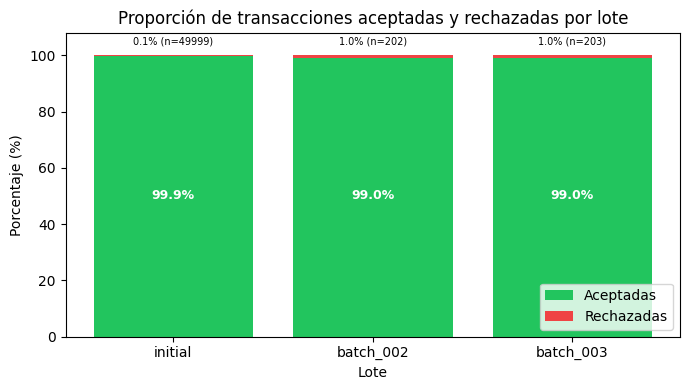

Respuesta: El lote inicial rechazó 0.1% (IC 95%: 0.1–0.1%, n=49999). Los lotes nuevos rechazan ~1%, pero sus IC son amplios (0.3–3.5%, 0.3–3.5%) por su tamaño reducido (n≈200), por lo que no se puede concluir que la calidad difiera del lote inicial.


In [0]:
# Tu solución. Calculá total = accepted_transactions + rejected_transactions.
# Un gráfico de barras apiladas al 100% puede facilitar la comparación de proporciones.

from pyspark.sql import functions as F

import matplotlib
import sys
for _sub in ['artist', 'backends', 'colors', 'figure', 'axes', 'lines', 'patches', 'text', 'ticker', 'cm', 'font_manager', 'transforms', 'path', 'markers', 'spines', 'legend', 'axis', 'scale', 'tight_layout', 'gridspec', 'units', 'dates', 'table', 'collections', 'contour', 'image', 'patheffects', 'rcsetup']:
    try:
        __import__(f'matplotlib.{_sub}')
        setattr(matplotlib, _sub, sys.modules[f'matplotlib.{_sub}'])
    except (ImportError, KeyError):
        pass
import matplotlib.pyplot as plt

calidad_lotes = spark.sql(f"""
WITH base AS (
SELECT source_batch_id AS lote, SUM(accepted_transactions) AS aceptadas,
SUM(rejected_transactions) AS rechazadas, SUM(accepted_transactions) + SUM(rejected_transactions) AS total
FROM {batch}
GROUP BY source_batch_id
),
prop AS(
SELECT *, aceptadas / total AS p_acep, rechazadas / total AS p_rech FROM base)
SELECT
lote, total, aceptadas, rechazadas,
ROUND(100 * p_acep, 3) AS pct_aceptada,
ROUND(100 * p_rech, 3) AS pct_rechazada,
ROUND(100 * (
(p_rech + POW(1.96,2)/(2*total)) / (1 + POW(1.96,2)/total)
- 1.96 * SQRT(p_rech*(1-p_rech)/total + POW(1.96,2)/(4*POW(total,2))) / (1 + POW(1.96,2)/total)
), 3) AS rechazo_ic_inf,
ROUND(100 * (
(p_rech + POW(1.96,2)/(2*total)) / (1 + POW(1.96,2)/total)
 + 1.96 * SQRT(p_rech*(1-p_rech)/total + POW(1.96,2)/(4*POW(total,2))) / (1 + POW(1.96,2)/total)
), 3) AS rechazo_ic_sup
FROM prop
ORDER BY CASE WHEN lote = 'initial' THEN 0 ELSE 1 END, lote
""")

display(calidad_lotes)

plot_data = calidad_lotes.toPandas()

fig, ax = plt.subplots(figsize=(7, 4))
x = list(range(len(plot_data)))
ax.bar(x, plot_data["pct_aceptada"], label="Aceptadas", color="#22c55e")
ax.bar(x, plot_data["pct_rechazada"], bottom=plot_data["pct_aceptada"], label="Rechazadas", color="#ef4444")
ax.set_xticks(x)
ax.set_xticklabels(plot_data["lote"])
ax.set_ylabel("Porcentaje (%)")
ax.set_xlabel("Lote")
ax.set_title("Proporción de transacciones aceptadas y rechazadas por lote")
ax.set_ylim(0, 108)
ax.legend(loc="lower right")
for i, (_, row) in enumerate(plot_data.iterrows()):
    ax.text(i, 50, f"{row['pct_aceptada']:.1f}%", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    ax.text(i, 103, f"{row['pct_rechazada']:.1f}% (n={int(row['total'])})", ha="center", va="bottom", fontsize=7)
fig.tight_layout()
plt.show()

ini = plot_data[plot_data["lote"] == "initial"].iloc[0]
nuevos = plot_data[plot_data["lote"] != "initial"]
ics = [f"{r['rechazo_ic_inf']:.1f}–{r['rechazo_ic_sup']:.1f}%" for _, r in nuevos.iterrows()]
print(f"Respuesta: El lote inicial rechazó {ini['pct_rechazada']:.1f}% (IC 95%: {ini['rechazo_ic_inf']:.1f}–{ini['rechazo_ic_sup']:.1f}%, n={int(ini['total'])}). "
      f"Los lotes nuevos rechazan ~1%, pero sus IC son amplios ({', '.join(ics)}) "
      f"por su tamaño reducido (n≈200), por lo que no se puede concluir que la calidad difiera del lote inicial.")

El lote inicial rechazo 0.1%, el batch_002 un 1%, y el batch_003 un 1%

## Criterios de entrega

Para cada consigna entregá: (1) la transformación de datos, (2) un gráfico, y (3) una conclusión de dos o tres oraciones que responda explícitamente la pregunta.

Cada gráfico debe tener título informativo, ejes y unidades legibles, categorías ordenadas cuando corresponda y una elección de color que no sea la única forma de comunicar el significado. No conviertas una tabla Silver completa a Pandas: agregá primero con Spark y convertí sólo el resultado pequeño.